# XgBoost for Regression

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, GridSearchCV, train_test_split, cross_val_predict
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score, accuracy_score, confusion_matrix
from xgboost import XGBRegressor, XGBClassifier

from redshift_fn import binDataFunc, eta_015
from dataset import training_set_1, training_set_2, training_set_3
from results import regression_results, plot_regression_scatter, classification_results, plot_classification_scatter

# RXGB-1


Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources: 918
Testing sources: 393
Fitting 10 folds for each of 27 candidates, totalling 270 fits

XGBoost GridSearchCV Results
Best CV RMSE: 0.2739359297886886
Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 800, 'subsample': 0.8}

Best XGBoost Parameters
Number of estimators: 800
Maximum depth: 5
Learning rate: 0.05

RXGB-1 Results:
{'eta_0.15': 8.9058524173028, 'eta_2sigma': 5.089058524173027, 'sigma': 0.11825497448444366, 'sigma_NMAD': 0.0521259568631649, 'R^2': 0.6867464184761047, 'MSE': 0.053069282323122025, 'RMSE': 0.23036771111230417, 'MAE': 0.10624560713768005}


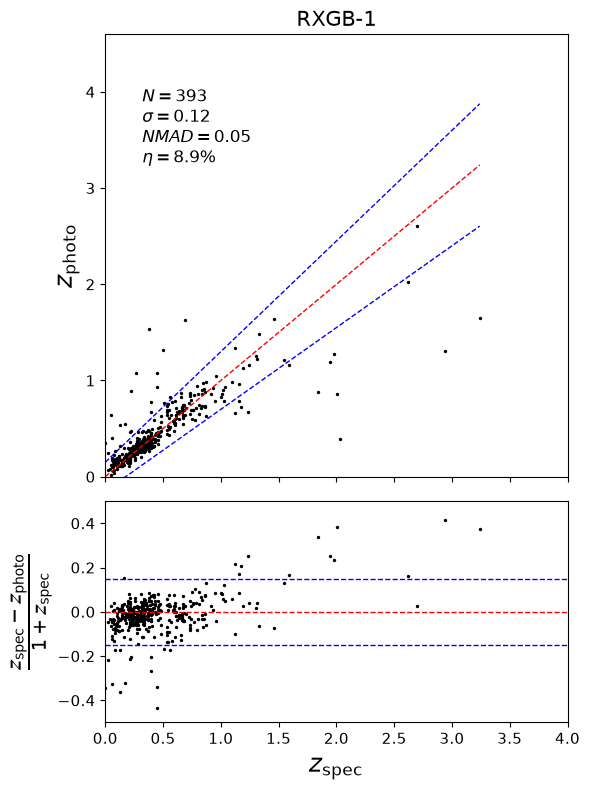

In [5]:
# Load data
file_path = "/home/sk/Projects/Astrophysics/data/ATLAS.csv"
X_train,X_test,y_train,y_test,test_indices,y=training_set_1(file_path)

# XGBoost regression model
model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter grid
param_grid = {
    "n_estimators": [200, 500, 800],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8],
    "colsample_bytree": [0.8]
}

# param_grid = {
#     "n_estimators": [200, 400, 600, 800, 1000, 1200],
#     "max_depth": [2, 3, 4, 5, 6, 8],
#     "learning_rate": [0.01, 0.03, 0.05, 0.07, 0.1],
#     "min_child_weight": [1, 3, 5],
#     "subsample": [0.7, 0.8, 0.9, 1.0],
#     "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
#     "gamma": [0, 0.1, 0.3],
#     "reg_alpha": [0, 0.01, 0.1],
#     "reg_lambda": [1, 1.5, 2]
# }

# Grid search with 10-fold CV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=10,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Fit the model
grid_search.fit(X_train, y_train)

# Best model
model = grid_search.best_estimator_
y_pred = model.predict(X_test)

# Remove invalid predictions if any
valid = np.isfinite(y_test) & np.isfinite(y_pred)
y_test_valid = y_test[valid]
y_pred_valid = y_pred[valid]

# GridSearchCV results
print("\nXGBoost GridSearchCV Results")
print("Best CV RMSE:", np.sqrt(-grid_search.best_score_))
print("Best parameters:", grid_search.best_params_)

# Model information
print("\nBest XGBoost Parameters")
print("Number of estimators:", model.n_estimators)
print("Maximum depth:", model.max_depth)
print("Learning rate:", model.learning_rate)

# regression results
results = regression_results(y_test_valid, y_pred_valid, test_name="RXGB-1" )
print(results)

# Plotting the results
plot_regression_scatter(y_test_valid, y_pred_valid, title="RXGB-1")

# RXGB-2

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources(ELAIS-S1): 495
Testing sources(CDFS): 816
Fitting 10 folds for each of 27 candidates, totalling 270 fits

XGBoost GridSearchCV Results
Best CV RMSE: 0.33783879792191396
Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 800, 'subsample': 0.8}

Best XGBoost Parameters
Number of estimators: 800
Maximum depth: 5
Learning rate: 0.1

RXGB-2 Results:
{'eta_0.15': 13.602941176470587, 'eta_2sigma': 5.392156862745098, 'sigma': 0.17805781960487366, 'sigma_NMAD': 0.06235835701227188, 'R^2': 0.3759663701057434, 'MSE': 0.10153549164533615, 'RMSE': 0.318646342588984, 'MAE': 0.1464536339044571}


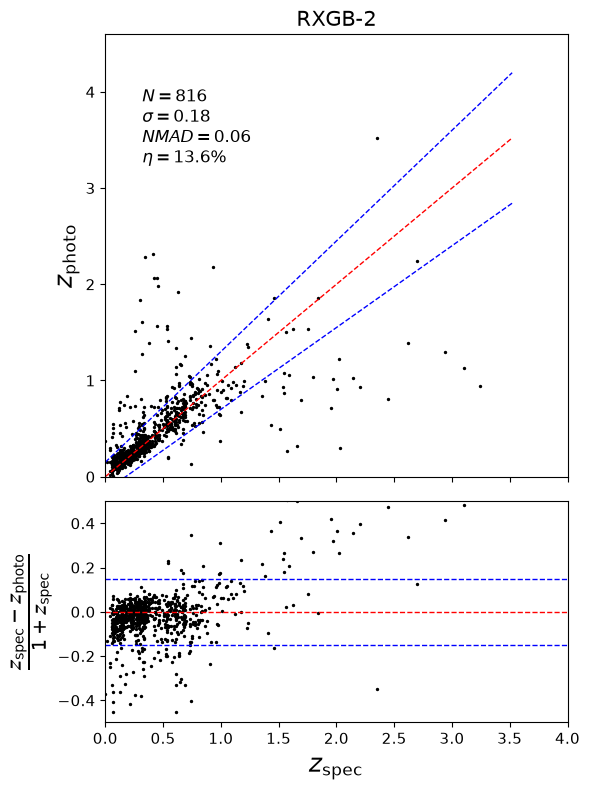

In [6]:
# Load data
file_path = "/home/sk/Projects/Astrophysics/data/ATLAS.csv"
X_train, X_test, y_train, y_test = training_set_2(file_path)

# XGBoost regression model
model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter grid
param_grid = {
    "n_estimators": [200, 500, 800],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8],
    "colsample_bytree": [0.8]
}

# Grid search with 10-fold CV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=10,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Fit the model
grid_search.fit(X_train, y_train)

# Best model
model = grid_search.best_estimator_
y_pred = model.predict(X_test)

# Remove invalid predictions if any
valid = np.isfinite(y_test) & np.isfinite(y_pred)
y_test_valid = y_test[valid]
y_pred_valid = y_pred[valid]

# GridSearchCV results
print("\nXGBoost GridSearchCV Results")
print("Best CV RMSE:", np.sqrt(-grid_search.best_score_))
print("Best parameters:", grid_search.best_params_)

# Model information
print("\nBest XGBoost Parameters")
print("Number of estimators:", model.n_estimators)
print("Maximum depth:", model.max_depth)
print("Learning rate:", model.learning_rate)

# regression results
results = regression_results(y_test_valid, y_pred_valid, test_name="RXGB-2" )
print(results)

# Plotting the results
plot_regression_scatter(y_test_valid, y_pred_valid, title="RXGB-2")

# RXGB-3

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources(CDFS): 816
Testing sources(ELAIS-S1): 495
Fitting 10 folds for each of 27 candidates, totalling 270 fits

XGBoost GridSearchCV Results
Best CV RMSE: 0.2605889400443006
Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 800, 'subsample': 0.8}

Best XGBoost Parameters
Number of estimators: 800
Maximum depth: 5
Learning rate: 0.03

RXGB-3 Results:
{'eta_0.15': 10.505050505050505, 'eta_2sigma': 5.05050505050505, 'sigma': 0.13322174549102783, 'sigma_NMAD': 0.054013870656490326, 'R^2': 0.5727154016494751, 'MSE': 0.08014484494924545, 'RMSE': 0.28309864879445373, 'MAE': 0.12458296865224838}


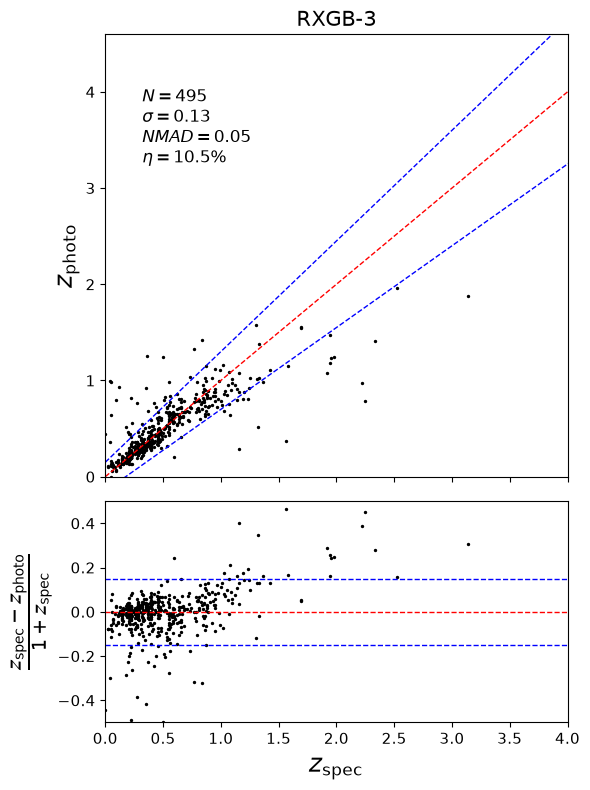

In [7]:
# Load data
file_path = "/home/sk/Projects/Astrophysics/data/ATLAS.csv"
X_train, X_test, y_train, y_test = training_set_3(file_path)

# XGBoost regression model
model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter grid
param_grid = {
    "n_estimators": [200, 500, 800],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8],
    "colsample_bytree": [0.8]
}

# Grid search with 10-fold CV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=10,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Fit the model
grid_search.fit(X_train, y_train)

# Best model
model = grid_search.best_estimator_
y_pred = model.predict(X_test)

# Remove invalid predictions if any
valid = np.isfinite(y_test) & np.isfinite(y_pred)
y_test_valid = y_test[valid]
y_pred_valid = y_pred[valid]

# GridSearchCV results
print("\nXGBoost GridSearchCV Results")
print("Best CV RMSE:", np.sqrt(-grid_search.best_score_))
print("Best parameters:", grid_search.best_params_)

# Model information
print("\nBest XGBoost Parameters")
print("Number of estimators:", model.n_estimators)
print("Maximum depth:", model.max_depth)
print("Learning rate:", model.learning_rate)

# regression results
results = regression_results(y_test_valid, y_pred_valid, test_name="RXGB-3" )
print(results)

# Plotting the results
plot_regression_scatter(y_test_valid, y_pred_valid, title="RXGB-3")

# XgBoost for Classification

# CXGB-1

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources: 918
Testing sources: 393
Number of classes: 15
Training classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Testing classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Fitting 10 folds for each of 36 candidates, totalling 360 fits

GridSearchCV Results
Best CV accuracy: 0.3779861442904921
Best parameters: {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 1000}

Best XGBoost parameters:
Number of estimators: 1000
Learning rate: 0.1
Maximum depth: 1
10-fold CV accuracy: 0.3779861442904921

CXGB1 Results:
eta_0.15: 8.6514
eta_2sigma: 3.8168
sigma: 0.1247
sigma_NMAD: 0.0489


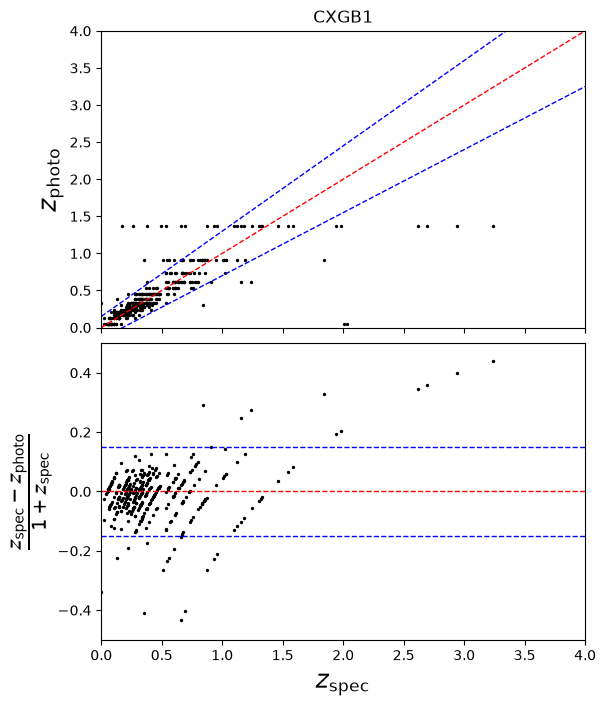

In [2]:
file_path="/home/sk/Projects/Astrophysics/data/ATLAS.csv"

# Load data and split
X_train,X_test,y_train,y_test,test_indices,y=training_set_1(file_path)

# Create 15 bins
y_all=np.concatenate([y_train,y_test])
y_all_binned,bin_edges,bin_values=binDataFunc(y_all.copy(),15)

n_train=len(y_train)
y_train_binned=y_all_binned[:n_train]
y_test_binned=y_all_binned[n_train:]

# Convert binned redshifts to integer class labels
y_train_class=np.searchsorted(bin_values,y_train_binned).astype(int)
y_test_class=np.searchsorted(bin_values,y_test_binned).astype(int)

print("Number of classes:",len(bin_values))
print("Training classes:",np.unique(y_train_class))
print("Testing classes:",np.unique(y_test_class))

# XGBoost classifier
xgb=XGBClassifier(
    objective="multi:softmax",
    num_class=len(bin_values),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter grid
param_grid={
    "n_estimators":[50,100,500,1000],
    "max_depth":[1,2,3],
    "learning_rate":[0.01,0.05,0.1]
}

# GridSearchCV
grid_search=GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Fit
grid_search.fit(X_train,y_train_class)

best_model=grid_search.best_estimator_

print("\nGridSearchCV Results")
print("Best CV accuracy:",grid_search.best_score_)
print("Best parameters:",grid_search.best_params_)

# Predict test set
y_pred_class=best_model.predict(X_test).astype(int)

# Convert predicted classes back to redshift
final_prediction=np.asarray(bin_values)[y_pred_class].astype(np.float32)

print("\nBest XGBoost parameters:")
print("Number of estimators:",best_model.n_estimators)
print("Learning rate:",best_model.learning_rate)
print("Maximum depth:",best_model.max_depth)
print("10-fold CV accuracy:",grid_search.best_score_)

# Classification results
results=classification_results(
    y_test_binned,
    final_prediction,
    test_name="CXGB1"
)

# Scatter plot using original continuous redshifts
y_test_spec=y[test_indices]

assert len(y_test_spec)==len(final_prediction)

plot_classification_scatter(
    y_test_spec,
    final_prediction,
    title="CXGB1"
)

# CXGB-2

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources(ELAIS-S1): 495
Testing sources(CDFS): 816
Number of classes: 15
Training classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Testing classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Fitting 10 folds for each of 36 candidates, totalling 360 fits

GridSearchCV Results
Best CV accuracy: 0.371795918367347
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50}

Best XGBoost parameters:
Number of estimators: 50
Learning rate: 0.05
Maximum depth: 3
10-fold CV accuracy: 0.371795918367347

CXGB2 Results:
Accuracy: 0.2684
eta_0.15: 11.5196
eta_2sigma: 5.8824
sigma: 0.1531
sigma_NMAD: 0.0754


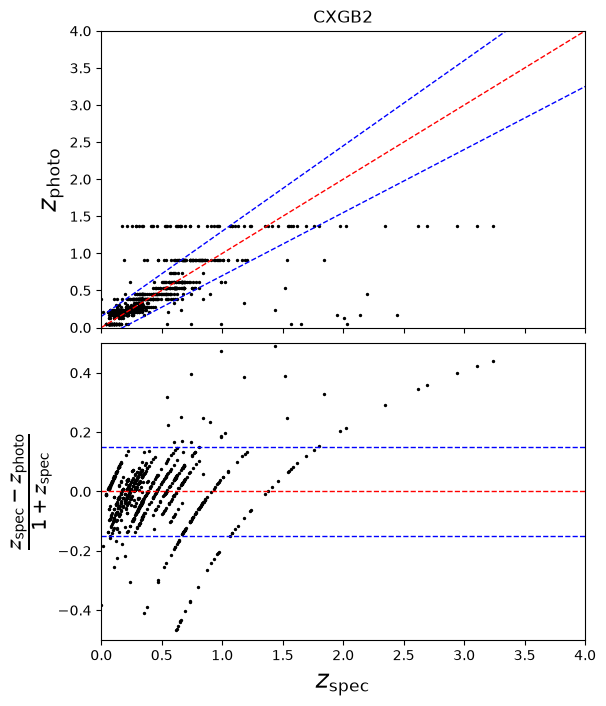

In [9]:
file_path="/home/sk/Projects/Astrophysics/data/ATLAS.csv"

# Load data and split
X_train,X_test,y_train,y_test=training_set_2(file_path)

# Create 15 bins
y_all=np.concatenate([y_train,y_test])
y_all_binned,bin_edges,bin_values=binDataFunc(y_all.copy(),15)

n_train=len(y_train)
y_train_binned=y_all_binned[:n_train]
y_test_binned=y_all_binned[n_train:]

# Convert binned redshifts to integer class labels
y_train_class=np.searchsorted(bin_values,y_train_binned).astype(int)
y_test_class=np.searchsorted(bin_values,y_test_binned).astype(int)

print("Number of classes:",len(bin_values))
print("Training classes:",np.unique(y_train_class))
print("Testing classes:",np.unique(y_test_class))

# XGBoost classifier
xgb=XGBClassifier(
    objective="multi:softmax",
    num_class=len(bin_values),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter grid
param_grid={
    "n_estimators":[50,100,500,1000],
    "max_depth":[1,2,3],
    "learning_rate":[0.01,0.05,0.1]
}

# GridSearchCV
grid_search=GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Fit
grid_search.fit(X_train,y_train_class)

best_model=grid_search.best_estimator_

print("\nGridSearchCV Results")
print("Best CV accuracy:",grid_search.best_score_)
print("Best parameters:",grid_search.best_params_)

# Predict test set
y_pred_class=best_model.predict(X_test).astype(int)

# Convert predicted classes back to redshift
final_prediction=np.asarray(bin_values)[y_pred_class].astype(np.float32)

print("\nBest XGBoost parameters:")
print("Number of estimators:",best_model.n_estimators)
print("Learning rate:",best_model.learning_rate)
print("Maximum depth:",best_model.max_depth)
print("10-fold CV accuracy:",grid_search.best_score_)

# Classification results
results=classification_results(
    y_test_binned,
    final_prediction,
    test_name="CXGB2"
)

# Scatter plot
plot_classification_scatter(
    y_test,
    final_prediction,
    title="CXGB2"
)

# CXGB-3

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources(CDFS): 816
Testing sources(ELAIS-S1): 495
Number of classes: 15
Training classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Testing classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Fitting 10 folds for each of 36 candidates, totalling 360 fits

GridSearchCV Results
Best CV accuracy: 0.3651008732309545
Best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 500}

Best XGBoost parameters:
Number of estimators: 500
Learning rate: 0.1
Maximum depth: 2
10-fold CV accuracy: 0.3651008732309545

CXGB3 Results:
Accuracy: 0.3192
eta_0.15: 12.5253
eta_2sigma: 4.4444
sigma: 0.1327
sigma_NMAD: 0.0737


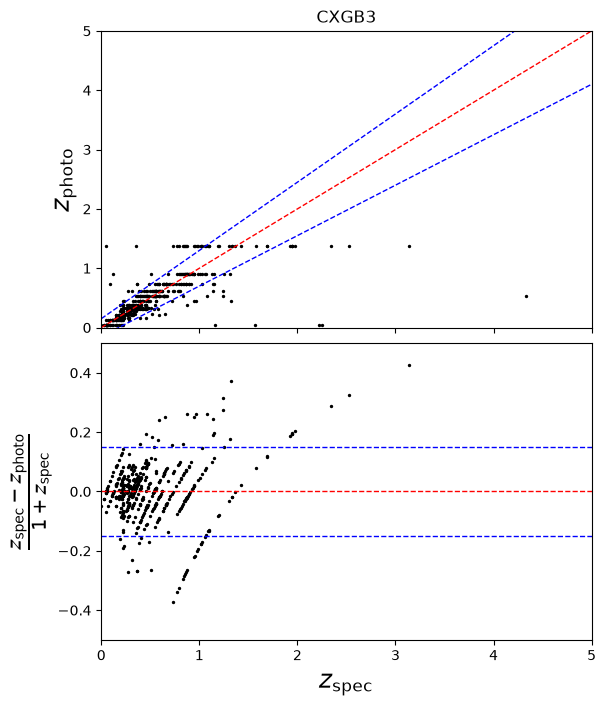

In [12]:
file_path="/home/sk/Projects/Astrophysics/data/ATLAS.csv"

# Load data and split
X_train,X_test,y_train,y_test=training_set_3(file_path)

# Create 15 bins
y_all=np.concatenate([y_train,y_test])
y_all_binned,bin_edges,bin_values=binDataFunc(y_all.copy(),15)

n_train=len(y_train)
y_train_binned=y_all_binned[:n_train]
y_test_binned=y_all_binned[n_train:]

# Convert binned redshifts to integer class labels
y_train_class=np.searchsorted(bin_values,y_train_binned).astype(int)
y_test_class=np.searchsorted(bin_values,y_test_binned).astype(int)

print("Number of classes:",len(bin_values))
print("Training classes:",np.unique(y_train_class))
print("Testing classes:",np.unique(y_test_class))

# XGBoost classifier
xgb=XGBClassifier(
    objective="multi:softmax",
    num_class=len(bin_values),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter grid
param_grid={
    "n_estimators":[50,100,500,1000],
    "max_depth":[1,2,3],
    "learning_rate":[0.01,0.05,0.1]
}

# GridSearchCV
grid_search=GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Fit
grid_search.fit(X_train,y_train_class)

best_model=grid_search.best_estimator_

print("\nGridSearchCV Results")
print("Best CV accuracy:",grid_search.best_score_)
print("Best parameters:",grid_search.best_params_)

# Predict test set
y_pred_class=best_model.predict(X_test).astype(int)

# Convert predicted classes back to redshift
final_prediction=np.asarray(bin_values)[y_pred_class].astype(np.float32)

print("\nBest XGBoost parameters:")
print("Number of estimators:",best_model.n_estimators)
print("Learning rate:",best_model.learning_rate)
print("Maximum depth:",best_model.max_depth)
print("10-fold CV accuracy:",grid_search.best_score_)

# Classification results
results=classification_results(
    y_test_binned,
    final_prediction,
    test_name="CXGB3"
)

# Scatter plot
plot_classification_scatter(
    y_test,
    final_prediction,
    title="CXGB3"
)